
# Data Collection and Cleaning Strategies in Logistics

## Week 1 Internship Project

**Dataset:** DataCo Smart Supply Chain Dataset

**Tools:** Python, Pandas, NumPy, Matplotlib and Seaborn

### Project Objective
To collect, inspect, clean, transform and validate logistics data to improve its quality and prepare it for further analysis.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas and basic libraries imported successfully!")


Pandas and basic libraries imported successfully!


In [2]:
# Importing OS to get list of directory content
import os

print(os.listdir('/content'))


['.config', 'Sales_Vs_Shipping_Duration.png', 'drive', 'shipping_Duration_Dayss.png', 'shipping_Duration_Days.png', 'shipping_Duration.png', 'BoxPlot_shipping_Duration.png', 'shipping_status.png', 'Histogram_shipping_Duration.png', 'sample_data']


In [3]:
# Mount Google colab to Drive content
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Get Path of the dataset Directory
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == 'DataCoSupplyChainDataset.csv':
            print(os.path.join(root, file))

/content/drive/MyDrive/DataCoSupplyChainDataset.csv


In [5]:
# Load Dataset from Google Drive
import pandas as pd

file_path = '/content/drive/MyDrive/DataCoSupplyChainDataset.csv'

df = pd.read_csv(file_path, encoding='latin-1')

display(df.shape)

(180519, 53)

In [6]:
# Initial Data Exploration

#1. Check dataset dimensions
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

#2. View first five records
print("\nFirst 5 records:")
display(df.head())

#3. View last five records
print("\nLast 5 records:")
display(df.tail())

#4. Check column names
print("\nColumn Names:")
display(df.columns)

#5. Check data types non-null values
print("\nData Types and Non-Null Values:")
display(df.info())

#6. Check missing values
print("\nMissing Values:")
display(df.isnull().sum())

#7. Check duplicate records
duplicate_count = df.duplicated().sum()
print("\nTotal duplicate rows:", duplicate_count)
print("Total records:", len(df))
display(duplicate_count)

#8. Generate statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (180519, 53)
Number of Rows: 180519
Number of Columns: 53

First 5 records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class



Last 5 records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.949997,383.980011,Shipping on time,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 18:54,Standard Class



Column Names:


Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

... (4 outputs left out)


Total duplicate rows: 0
Total records: 180519


np.int64(0)


Statistical Summary:


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [7]:
# Missing Value Analysis

#1. Calculate missing values
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

#2. Combine into a DataFrame for better display
missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percent
})

#3. Filter out columns with 0 missing values
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

if missing_df.empty:
    print("No missing values found in the dataset!")
else:
    print("Columns with missing values:")

display(missing_df)

Columns with missing values:


,Missing Values,Percentage (%)
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662


In [8]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Working copy created successfully!
Original shape: (180519, 53)
Working copy shape: (180519, 53)


In [9]:
# Working on Unnecessary Columns

#1. Display the 'Order Zipcode' and 'Product Description' columns properly on separate lines
print(" BEFORE DROPPING")
display(df_clean[['Order Zipcode', 'Product Description']])
print("Shape:", df_clean.shape)

#2. Droping Unnecessary Columns
df_clean.drop(
    columns=['Product Description', 'Order Zipcode'],
    inplace=True
)

print("Unnecessary columns removed!")
display("New shape:", df_clean.shape)

#3. After droping
print("AFTER DROPPING")
display(df_clean.head())
print("Shape:", df_clean.shape)




 BEFORE DROPPING


,Order Zipcode,Product Description
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
...,...,...
180514,NaN,NaN
180515,NaN,NaN
180516,NaN,NaN
180517,NaN,NaN


Shape: (180519, 53)
Unnecessary columns removed!


'New shape:'

(180519, 51)

AFTER DROPPING


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


Shape: (180519, 51)


In [10]:
# Analysing Missing Values

#1. Check remaining missing values

missing_values = df_clean.isnull().sum()
display(missing_values[missing_values > 0])

#2. Handle missing values

df_clean['Customer Lname'] = (
    df_clean['Customer Lname'].fillna('Unknown')
)

df_clean['Customer Zipcode'] = (
    df_clean['Customer Zipcode'].fillna('Unknown').astype(str)
)

print("\nMissing values handled successfully!")

#3. Verifying remaining missing values

print("\n Remaining missing values:")
print(df_clean.isnull().sum().sum())

,0
Customer Lname,8
Customer Zipcode,3



Missing values handled successfully!

 Remaining missing values:
0


In [11]:
# Find columns containing date or time in their names

date_columns = [
    col for col in df_clean.columns
    if 'date' in col.lower() or 'time' in col.lower()
]

print("Date-related columns:")
print(date_columns)
display(df[['order date (DateOrders)', 'shipping date (DateOrders)']])


# Convert date columns into datetime format

date_columns = [
    'order date (DateOrders)',
    'shipping date (DateOrders)'
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors='coerce')

print("\nDate columns converted successfully!")

# Check the data types
display(df_clean[date_columns].dtypes)

Date-related columns:
['order date (DateOrders)', 'shipping date (DateOrders)']


,order date (DateOrders),shipping date (DateOrders)
0,1/31/2018 22:56,2/3/2018 22:56
1,1/13/2018 12:27,1/18/2018 12:27
2,1/13/2018 12:06,1/17/2018 12:06
3,1/13/2018 11:45,1/16/2018 11:45
4,1/13/2018 11:24,1/15/2018 11:24
...,...,...
180514,1/16/2016 3:40,1/20/2016 3:40
180515,1/16/2016 1:34,1/19/2016 1:34
180516,1/15/2016 21:00,1/20/2016 21:00
180517,1/15/2016 20:18,1/18/2016 20:18



Date columns converted successfully!


,0
order date (DateOrders),datetime64[ns]
shipping date (DateOrders),datetime64[ns]


In [12]:
# Convert ZIP codes into string format
# . A ZIP code is an identifier, not a numerical quantity
df_clean['Customer Zipcode'] = (
    pd.to_numeric(df_clean['Customer Zipcode'], errors='coerce')
    .astype('Int64')
    .astype('string')
    .fillna('Unknown')
)

print("ZIP codes converted successfully!")

print("Data type:", df_clean['Customer Zipcode'].dtype)
print("Missing values:", df_clean['Customer Zipcode'].isnull().sum())

display(df_clean[['Customer Zipcode']].head())

ZIP codes converted successfully!
Data type: string
Missing values: 0


,Customer Zipcode
0,725
1,725
2,95125
3,90027
4,725


In [13]:
# Calculate shipping duration in days

df_clean['Shipping Duration'] = (
    df_clean['shipping date (DateOrders)'] -
    df_clean['order date (DateOrders)']
).dt.total_seconds() / (24 * 60 * 60)

display(df_clean[
    ['order date (DateOrders)',
     'shipping date (DateOrders)',
     'Shipping Duration']
].head(10))


,order date (DateOrders),shipping date (DateOrders),Shipping Duration
0,2018-01-31 22:56:00,2018-02-03 22:56:00,3.0
1,2018-01-13 12:27:00,2018-01-18 12:27:00,5.0
2,2018-01-13 12:06:00,2018-01-17 12:06:00,4.0
3,2018-01-13 11:45:00,2018-01-16 11:45:00,3.0
4,2018-01-13 11:24:00,2018-01-15 11:24:00,2.0
5,2018-01-13 11:03:00,2018-01-19 11:03:00,6.0
6,2018-01-13 10:42:00,2018-01-15 10:42:00,2.0
7,2018-01-13 10:21:00,2018-01-15 10:21:00,2.0
8,2018-01-13 10:00:00,2018-01-16 10:00:00,3.0
9,2018-01-13 09:39:00,2018-01-15 09:39:00,2.0


In [14]:

# Check shipping duration statistics

print(df_clean['Shipping Duration'].describe())

# Count negative shipping durations
negative_duration = (
    df_clean['Shipping Duration'] < 0
).sum()

print("\nNegative shipping durations:", negative_duration)

# Count missing durations
print("Missing durations:",
      df_clean['Shipping Duration'].isnull().sum())


count    180519.000000
mean          3.498826
std           1.617394
min           0.500000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Shipping Duration, dtype: float64

Negative shipping durations: 0
Missing durations: 0


In [15]:
# Analyzing Matching and non matching records with difference calculation

#1. Calculate the difference between 'Days for shipping (real)' and our calculated 'Shipping Duration'
df_clean['Duration Validation Difference'] = df_clean['Days for shipping (real)'] - df_clean['Shipping Duration']

#2. Count exact matches
exact_matches = (df_clean['Days for shipping (real)'] == df_clean['Shipping Duration']).sum()

#3. Count matches when rounded to nearest integer
rounded_matches = (df_clean['Days for shipping (real)'] == df_clean['Shipping Duration'].round()).sum()

print(f"Total orders analyzed: {len(df_clean)}")
print(f"Exact matches: {exact_matches} ({exact_matches / len(df_clean) * 100:.2f}%)")
print(f"Matches when rounded to the nearest integer: {rounded_matches} ({rounded_matches / len(df_clean) * 100:.2f}%)")

#4. Describe the differences
print("\nSummary statistics of the differences (Real - Calculated):")
print(df_clean['Duration Validation Difference'].describe())

#5. Display a sample where they don't match exactly
if exact_matches < len(df_clean):
    print("\nSample records with discrepancies:")
    display(
        df_clean[
            df_clean['Days for shipping (real)'] !=
            df_clean['Shipping Duration']
        ][
            ['order date (DateOrders)',
             'shipping date (DateOrders)',
             'Days for shipping (real)',
             'Shipping Duration',
             'Duration Validation Difference']
    ].head(5))

#6. Non Matching records
non_matching = len(df_clean) - exact_matches

display(f"Non-matching records: {non_matching}")
display(f"Non-matching percentage: {non_matching / len(df_clean) * 100:.2f}%")


Total orders analyzed: 180519
Exact matches: 170782 (94.61%)
Matches when rounded to the nearest integer: 175862 (97.42%)

Summary statistics of the differences (Real - Calculated):
count    180519.000000
mean         -0.001172
std           0.116118
min          -0.500000
25%           0.000000
50%           0.000000
75%           0.000000
max           0.500000
Name: Duration Validation Difference, dtype: float64

Sample records with discrepancies:


,order date (DateOrders),shipping date (DateOrders),Days for shipping (real),Shipping Duration,Duration Validation Difference
19,2018-01-13 06:09:00,2018-01-13 18:09:00,0,0.5,-0.5
20,2018-01-13 05:48:00,2018-01-13 17:48:00,0,0.5,-0.5
38,2018-01-12 23:30:00,2018-01-13 11:30:00,1,0.5,0.5
39,2018-01-12 23:09:00,2018-01-13 11:09:00,1,0.5,0.5
40,2018-01-12 22:48:00,2018-01-13 10:48:00,1,0.5,0.5


'Non-matching records: 9737'

'Non-matching percentage: 5.39%'

In [16]:
# Checking Delivery performance

#1. Calculate difference between actual and scheduled shipping

df_clean['Scheduled Difference'] = (
    df_clean['Days for shipping (real)'] -
    df_clean['Days for shipment (scheduled)']
)

#2. Classify shipping performance

df_clean['Shipping Status'] = np.select(
    [
        df_clean['Scheduled Difference'] < 0,
        df_clean['Scheduled Difference'] == 0,
        df_clean['Scheduled Difference'] > 0
    ],
    [
        'Early',
        'On Time',
        'Late'
    ],
    default='Unknown'
)

#3. Display sample results

display(
    df_clean[
        ['Days for shipping (real)',
         'Days for shipment (scheduled)',
         'Scheduled Difference',
         'Shipping Status']
    ].head(15)
)



,Days for shipping (real),Days for shipment (scheduled),Scheduled Difference,Shipping Status
0,3,4,-1,Early
1,5,4,1,Late
2,4,4,0,On Time
3,3,4,-1,Early
4,2,4,-2,Early
5,6,4,2,Late
6,2,1,1,Late
7,2,1,1,Late
8,3,2,1,Late
9,2,1,1,Late


In [17]:
#  Shipping status summary

#1. Calculate shipping status counts
status_counts = df_clean['Shipping Status'].value_counts()

#2. Calculate shipping status percentages
status_percentages = (
    df_clean['Shipping Status']
    .value_counts(normalize=True) * 100
).round(2)

#3. Create summary table
shipping_summary = pd.DataFrame({
    'Total Orders': status_counts,
    'Percentage (%)': status_percentages
})

display(shipping_summary)


,Total Orders,Percentage (%)
Shipping Status,,
Late,103400,57.28
Early,43366,24.02
On Time,33753,18.70


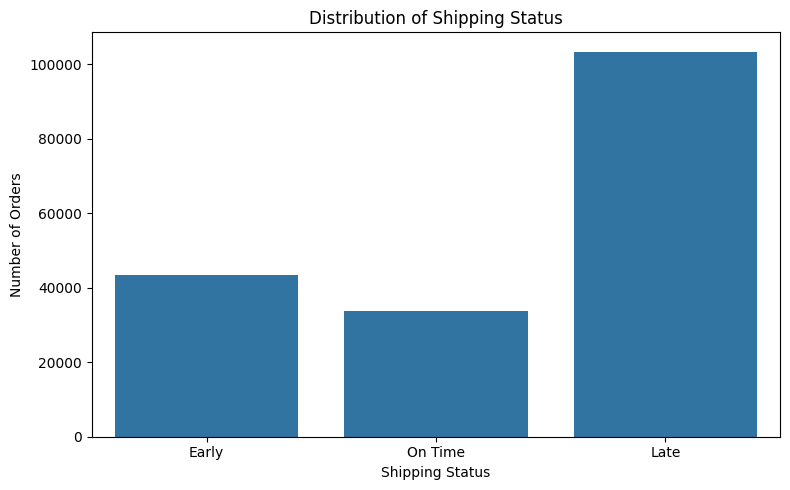

In [18]:
#Distribution of Shipping Duration
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Shipping Status',
    order=['Early', 'On Time', 'Late']
)

plt.title('Distribution of Shipping Status')
plt.xlabel('Shipping Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.savefig(
    'shipping_status.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

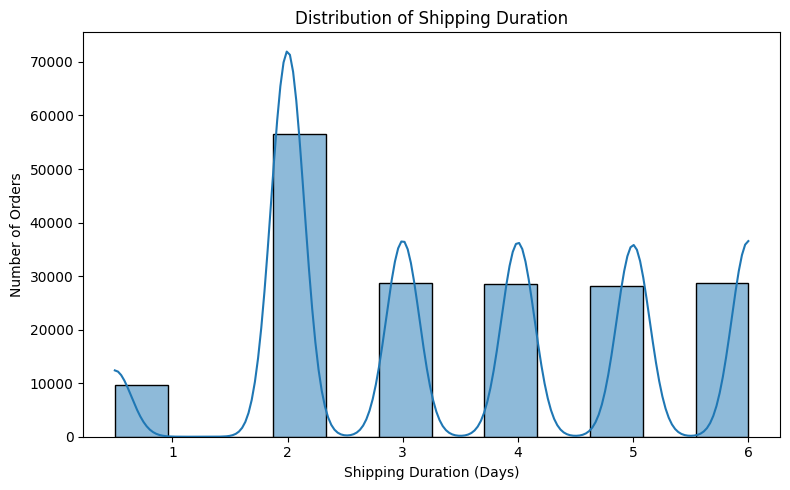

In [19]:
# Histogram of Shipping Duration

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Shipping Duration',
    bins=12,
    kde=True
)

plt.title('Distribution of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.savefig(
    'Histogram_shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

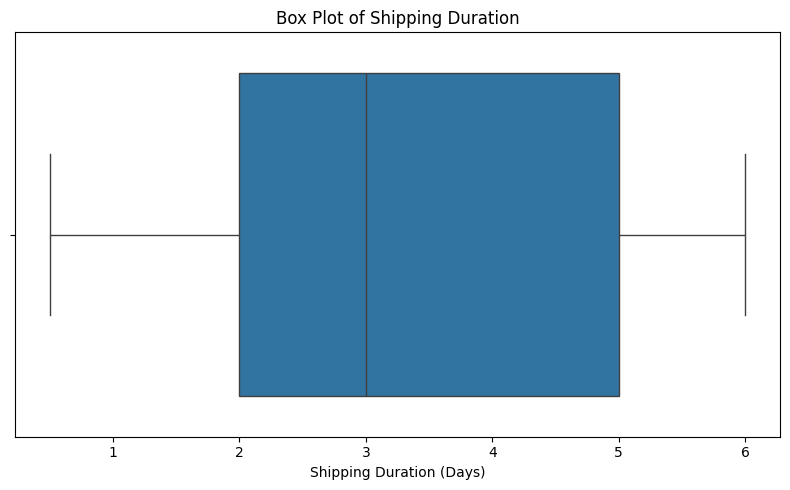

In [20]:
# Box Plot of Shipping Duration

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Shipping Duration'
)

plt.title('Box Plot of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')

plt.tight_layout()
plt.savefig(
    'BoxPlot_shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

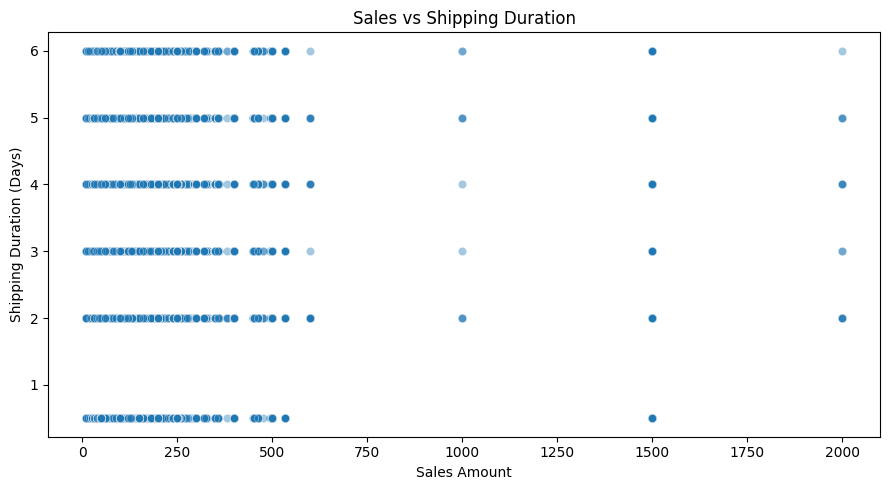

In [21]:
# Scatter Plot: Sales vs Shipping Duration
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x='Sales',
    y='Shipping Duration',
    alpha=0.4
)

plt.title('Sales vs Shipping Duration')
plt.xlabel('Sales Amount')
plt.ylabel('Shipping Duration (Days)')

plt.tight_layout()
plt.savefig(
    'Sales_Vs_Shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [22]:
df_clean


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Shipping Duration,Duration Validation Difference,Scheduled Difference,Shipping Status
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-02-03 22:56:00,Standard Class,3.0,0.0,-1,Early
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-18 12:27:00,Standard Class,5.0,0.0,1,Late
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-17 12:06:00,Standard Class,4.0,0.0,0,On Time
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-16 11:45:00,Standard Class,3.0,0.0,-1,Early
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-15 11:24:00,Standard Class,2.0,0.0,-2,Early
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-20 03:40:00,Standard Class,4.0,0.0,0,On Time
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-19 01:34:00,Second Class,3.0,0.0,1,Late
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-20 21:00:00,Standard Class,5.0,0.0,1,Late
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-18 20:18:00,Standard Class,3.0,0.0,-1,Early


In [23]:

print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes.value_counts())


Final dataset shape: (180519, 55)

Missing values:
0

Duplicate rows:
0

Data types:
object            23
int64             15
float64           14
datetime64[ns]     2
string[python]     1
Name: count, dtype: int64


## Summary of Work Completed So Far

1. **Data Collection & Initial Inspection**
   - Mounted Google Drive and successfully loaded the **DataCo Smart Supply Chain Dataset** containing **180,519 rows** and **53 columns**.
   - Inspected missing value percentages, duplicate rows, and column data types.

2. **Data Cleaning & Handling Missing Values**
   - Dropped unnecessary/highly sparse columns: `Product Description` (100% missing) and `Order Zipcode` (86.2% missing).
   - Handled remaining missing values: filled missing `Customer Lname` with `'Unknown'` and resolved `Customer Zipcode` missing entries.
   - Converted standard numeric ZIP codes to string representation for consistency.

3. **Data Transformation & Feature Engineering**
   - Converted date features (`order date (DateOrders)` and `shipping date (DateOrders)`) into proper datetime formats.
   - Engineered `Shipping Duration` (actual days taken for shipping based on datetime difference).
   - Created validation metrics to cross-verify our calculated duration with the dataset's native `Days for shipping (real)` (showing a **94.61% exact match** rate and **97.42% approximate match** rate within decimal/integer rounding offsets).

4. **Delivery Performance Classification**
   - Calculated the gap between scheduled and actual delivery days (`Scheduled Difference`).
   - Segmented deliveries into **Early** (~24.02%), **On Time** (~18.70%), and **Late** (~57.28%) categories.

5. **Exploratory Visualizations**
   - Plotted delivery performance distribution charts (Bar charts, Histograms, Box Plots, and Sales vs. Shipping Duration scatter plots) and saved them locally as `shipping_status.png`.